In [65]:
import numpy as np
import matplotlib.pyplot as plt
import os 

In [66]:
data_map = {"cifar10": "CIFAR-10"}

In [67]:
# Dataset 
dataset = "cifar10"
N = 50000
N_val = 10000
K = 10

num_trials = 2
epochs = 250

# Network
act = "ReLU"
init = "orthogonal"
init_scale = 1e-1
lr = 1e-2
comp_sub = 2
r = 10

batch_size = 128



## Load full-model training results

In [68]:
num_full_params = "50.4M"
num_comp_params = "14.9M"


data_dir = dataset + '_K_' + str(K) + '_N_' + str(N)
net_dir = act + '_vgg16_' + init + '_init_scale_' + str(init_scale) + '_eta_' + str(lr)
fc_net_dir = act + '_vgg16_frozen_conv_' + init + '_init_scale_' + str(init_scale) + '_eta_' + str(lr)


orig_net_dir = os.path.join(net_dir, 'orig_model')
comp_net_dir = os.path.join(net_dir, 'compressed_model_rank_' + str(r) + '_subspace_' + str(comp_sub))
comp_rand_net_dir = os.path.join(net_dir, 'compressed_model_rank_' + str(r) + '_subspace_None')

orig_load_dir = os.path.join('./results', data_dir, orig_net_dir)
comp_load_dir = os.path.join('./results', data_dir, comp_net_dir)
comp_rand_load_dir = os.path.join('./results', data_dir, comp_rand_net_dir)

In [69]:
orig_val_accs = np.zeros((num_trials, epochs))
comp_val_accs = np.zeros((num_trials, epochs))
comp_rand_val_accs = np.zeros((num_trials, epochs))

orig_train_losses = np.zeros((num_trials, epochs))
comp_train_losses = np.zeros((num_trials, epochs))
comp_rand_train_losses = np.zeros((num_trials, epochs))

for i in range(num_trials):
    orig_accs = np.load(os.path.join(orig_load_dir, 'trial_' + str(i + 1) + '_accs.npz'))
    comp_accs = np.load(os.path.join(comp_load_dir, 'trial_' + str(i + 1) + '_accs.npz'))
    comp_rand_accs = np.load(os.path.join(comp_rand_load_dir, 'trial_' + str(i + 1) + '_accs.npz'))
    
    orig_val_accs[i, :] = orig_accs['val_accs']
    comp_val_accs[i, :] = comp_accs['val_accs']
    comp_rand_val_accs[i, :] = comp_rand_accs['val_accs']
    
    
    orig_losses = np.load(os.path.join(orig_load_dir, 'trial_' + str(i + 1) + '_losses.npz'))
    comp_losses = np.load(os.path.join(comp_load_dir, 'trial_' + str(i + 1) + '_losses.npz'))
    comp_rand_losses = np.load(os.path.join(comp_rand_load_dir, 'trial_' + str(i + 1) + '_losses.npz'))
    
    orig_train_losses[i, :] = orig_losses['train_losses'] / (N / batch_size)
    comp_train_losses[i, :] = comp_losses['train_losses'] / (N / batch_size)
    comp_rand_train_losses[i, :] = comp_rand_losses['train_losses'] / (N / batch_size)


In [70]:
# Original model
mean_orig_val_accs = np.mean(orig_val_accs, axis=0)
std_orig_val_accs = np.std(orig_val_accs, axis=0)

max_orig_val_accs = np.max(orig_val_accs, axis=1)
std_max_orig_val_accs = np.std(max_orig_val_accs)

mean_orig_train_losses = np.mean(orig_train_losses, axis=0)
std_orig_train_losses = np.std(orig_train_losses, axis=0)


# Compressed model
mean_comp_val_accs = np.mean(comp_val_accs, axis=0)
std_comp_val_accs = np.std(comp_val_accs, axis=0)

max_comp_val_accs = np.max(comp_val_accs, axis=1)
std_max_comp_val_accs = np.std(max_comp_val_accs)

mean_comp_train_losses = np.mean(comp_train_losses, axis=0)
std_comp_train_losses = np.std(comp_train_losses, axis=0)


# Compressed model with random subspace
mean_comp_rand_val_accs = np.mean(comp_rand_val_accs, axis=0)
std_comp_rand_val_accs = np.std(comp_rand_val_accs, axis=0)

max_comp_rand_val_accs = np.max(comp_rand_val_accs, axis=1)
std_max_comp_rand_val_accs = np.std(max_comp_rand_val_accs)

mean_comp_rand_train_losses = np.mean(comp_rand_train_losses, axis=0)
std_comp_rand_train_losses = np.std(comp_rand_train_losses, axis=0)


print("Max val accuracies for original model: (", np.mean(max_orig_val_accs), " ", std_max_orig_val_accs, ")")
print("Max val accuracies for compressed model (S perp init.): (", np.mean(max_comp_val_accs), " ", std_max_comp_val_accs, ")")
print("Max val accuracies for original model: (random subspace init.):", np.mean(max_comp_rand_val_accs), " ", std_max_comp_rand_val_accs, ")")

Max val accuracies for original model: ( 93.08   0.21999999999999886 )
Max val accuracies for compressed model (S perp init.): ( 90.36   0.21999999999999886 )
Max val accuracies for original model: (random subspace init.): 88.66499999999999   0.19500000000000028 )


## Load frozen conv training results

In [71]:
fc_num_full_params = "35.7M"
fc_num_comp_params = "220K"


data_dir = dataset + '_K_' + str(K) + '_N_' + str(N)
fc_net_dir = act + '_vgg16_frozen_conv_' + init + '_init_scale_' + str(init_scale) + '_eta_' + str(lr)

fc_orig_net_dir = os.path.join(fc_net_dir, 'orig_model')
fc_comp_net_dir = os.path.join(fc_net_dir, 'compressed_model_rank_' + str(r) + '_subspace_' + str(comp_sub))
fc_comp_rand_net_dir = os.path.join(fc_net_dir, 'compressed_model_rank_' + str(r) + '_subspace_None')

fc_orig_load_dir = os.path.join('./results', data_dir, fc_orig_net_dir)
fc_comp_load_dir = os.path.join('./results', data_dir, fc_comp_net_dir)
fc_comp_rand_load_dir = os.path.join('./results', data_dir, fc_comp_rand_net_dir)

In [72]:
# Val accuracies
fc_orig_val_accs = np.zeros((num_trials, epochs))
fc_comp_val_accs = np.zeros((num_trials, epochs))
fc_comp_rand_val_accs = np.zeros((num_trials, epochs))

# Train losses
fc_orig_train_losses = np.zeros((num_trials, epochs))
fc_comp_train_losses = np.zeros((num_trials, epochs))
fc_comp_rand_train_losses = np.zeros((num_trials, epochs))

for i in range(num_trials):
    # Load validation accuracies
    fc_orig_accs = np.load(os.path.join(fc_orig_load_dir, 'trial_' + str(i + 1) + '_accs.npz'))
    fc_comp_accs = np.load(os.path.join(fc_comp_load_dir, 'trial_' + str(i + 1) + '_accs.npz'))
    fc_comp_rand_accs = np.load(os.path.join(fc_comp_rand_load_dir, 'trial_' + str(i + 1) + '_accs.npz'))
    
    fc_orig_val_accs[i, :] = fc_orig_accs['val_accs']
    fc_comp_val_accs[i, :] = fc_comp_accs['val_accs']
    fc_comp_rand_val_accs[i, :] = fc_comp_rand_accs['val_accs']
    
    # Load train losses
    fc_orig_losses = np.load(os.path.join(fc_orig_load_dir, 'trial_' + str(i + 1) + '_losses.npz'))
    fc_comp_losses = np.load(os.path.join(fc_comp_load_dir, 'trial_' + str(i + 1) + '_losses.npz'))
    fc_comp_rand_losses = np.load(os.path.join(fc_comp_rand_load_dir, 'trial_' + str(i + 1) + '_losses.npz'))
    
    fc_orig_train_losses[i, :] = fc_orig_losses['train_losses'] / (N / batch_size)
    fc_comp_train_losses[i, :] = fc_comp_losses['train_losses'] / (N / batch_size)
    fc_comp_rand_train_losses[i, :] = fc_comp_rand_losses['train_losses'] / (N / batch_size)


In [73]:
# Original model
mean_fc_orig_val_accs = np.mean(fc_orig_val_accs, axis=0)
std_fc_orig_val_accs = np.std(fc_orig_val_accs, axis=0)

max_fc_orig_val_accs = np.max(fc_orig_val_accs, axis=1)
std_max_fc_orig_val_accs = np.std(max_fc_orig_val_accs)

mean_fc_orig_train_losses = np.mean(fc_orig_train_losses, axis=0)
std_fc_orig_train_losses = np.std(fc_orig_train_losses, axis=0)


# Compressed model
mean_fc_comp_val_accs = np.mean(fc_comp_val_accs, axis=0)
std_fc_comp_val_accs = np.std(fc_comp_val_accs, axis=0)

max_fc_comp_val_accs = np.max(fc_comp_val_accs, axis=1)
std_max_fc_comp_val_accs = np.std(max_fc_comp_val_accs)

mean_fc_comp_train_losses = np.mean(fc_comp_train_losses, axis=0)
std_fc_comp_train_losses = np.std(fc_comp_train_losses, axis=0)


# Compressed model with random subspace
mean_fc_comp_rand_val_accs = np.mean(fc_comp_rand_val_accs, axis=0)
std_fc_comp_rand_val_accs = np.std(fc_comp_rand_val_accs, axis=0)

max_fc_comp_rand_val_accs = np.max(fc_comp_rand_val_accs, axis=1)
std_max_fc_comp_rand_val_accs = np.std(max_fc_comp_rand_val_accs)

mean_fc_comp_rand_train_losses = np.mean(fc_comp_rand_train_losses, axis=0)
std_fc_comp_rand_train_losses = np.std(fc_comp_rand_train_losses, axis=0)


print("Max val accuracies for original model: (", np.mean(max_fc_orig_val_accs), " ", std_max_fc_orig_val_accs, ")")
print("Max val accuracies for compressed model (S perp init.): (", np.mean(max_fc_comp_val_accs), " ", std_max_fc_comp_val_accs, ")")
print("Max val accuracies for original model: (random subspace init.):", np.mean(max_fc_comp_rand_val_accs), " ", std_max_fc_comp_rand_val_accs, ")")

Max val accuracies for original model: ( 85.775   0.3950000000000031 )
Max val accuracies for compressed model (S perp init.): ( 76.16   0.36999999999999744 )
Max val accuracies for original model: (random subspace init.): 72.455   0.8850000000000051 )


/tmp/ipykernel_792951/2808861267.py:36: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  ax1.legend([num_full_params, '_', num_comp_params, '_', num_comp_params], fontsize=18) #, bbox_to_anchor=(0.2, 0.3))
/tmp/ipykernel_792951/2808861267.py:57: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  ax2.legend([fc_num_full_params, '_', fc_num_comp_params, '_', fc_num_comp_params], fontsize=18) #, loc='center')


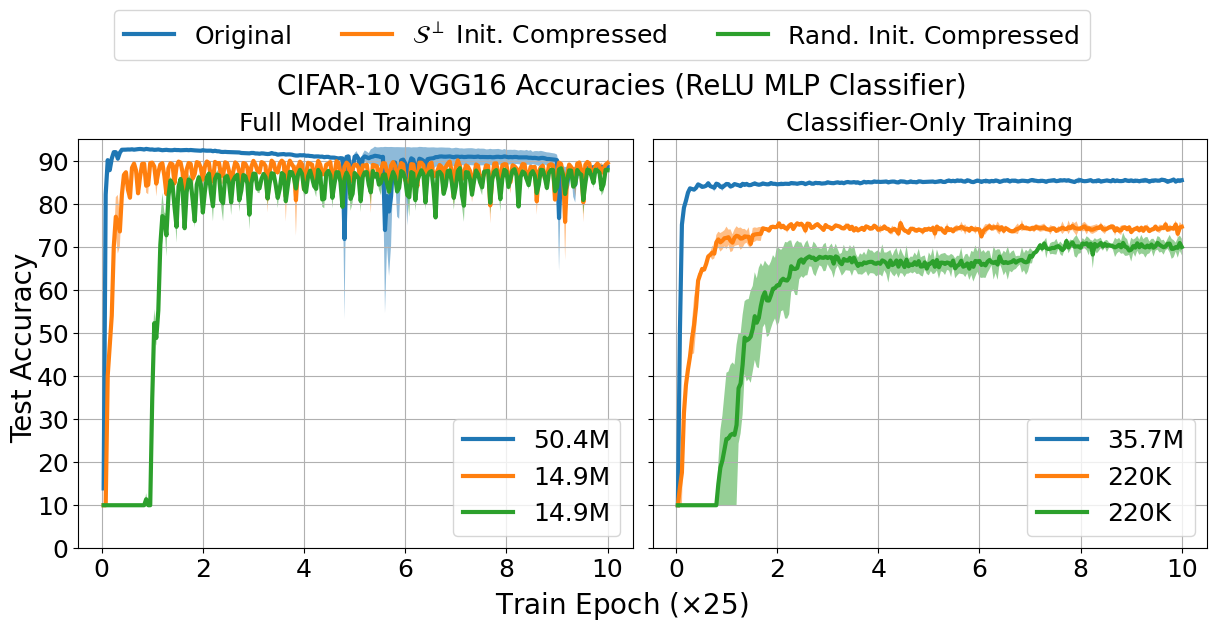

In [74]:
lw = 3

savefig = False

save_net_dir = act + '_vgg16_' + init + '_init_scale_' + str(init_scale)
save_dir = os.path.join('./figs', data_dir, save_net_dir)
if savefig and not os.path.exists(save_dir):
    os.makedirs(save_dir)


# Full model test accuracy
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)

ax1.plot(np.arange(1, epochs + 1), mean_orig_val_accs, label='Original', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_orig_val_accs - std_orig_val_accs, mean_orig_val_accs + std_orig_val_accs, alpha=0.5, linewidth=lw)

ax1.plot(np.arange(1, epochs + 1), mean_comp_val_accs, label=r'$\mathcal{S}^\perp$ Init. Compressed', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_comp_val_accs - std_comp_val_accs, mean_comp_val_accs + std_comp_val_accs, alpha=0.5, linewidth=lw)

ax1.plot(np.arange(1, epochs + 1), mean_comp_rand_val_accs, label='Rand. Init. Compressed', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_comp_rand_val_accs - std_comp_rand_val_accs, mean_comp_rand_val_accs + std_comp_rand_val_accs, alpha=0.5, linewidth=lw)


xticks = np.linspace(0, epochs, (epochs // 50) + 1)
xticklabels = np.linspace(0, epochs // 25, epochs // 50 + 1, dtype=int)

ax1.set_xticks(xticks, labels=xticklabels, fontsize=18)
ax1.set_yticks(np.linspace(0, 90, 10, dtype=int), labels=np.linspace(0, 90, 10, dtype=int), fontsize=18)
ax1.set_ylim([0, 95])


ax1.set_title('Full Model Training', fontsize=18)
ax1.grid('on')
ax1.legend([num_full_params, '_', num_comp_params, '_', num_comp_params], fontsize=18) #, bbox_to_anchor=(0.2, 0.3))


# Frozen conv test accuracy
ax2 = fig.add_subplot(122, sharey=ax1)

ax2.plot(np.arange(1, epochs + 1), mean_fc_orig_val_accs, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_fc_orig_val_accs - std_fc_orig_val_accs, mean_fc_orig_val_accs + std_fc_orig_val_accs, alpha=0.5, linewidth=lw)

ax2.plot(np.arange(1, epochs + 1), mean_fc_comp_val_accs, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_fc_comp_val_accs - std_fc_comp_val_accs, mean_fc_comp_val_accs + std_fc_comp_val_accs, alpha=0.5, linewidth=lw)

ax2.plot(np.arange(1, epochs + 1), mean_fc_comp_rand_val_accs, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_fc_comp_rand_val_accs - std_fc_comp_rand_val_accs, mean_fc_comp_rand_val_accs + std_fc_comp_rand_val_accs, alpha=0.5, linewidth=lw)


ax2.set_xticks(xticks, labels=xticklabels, fontsize=18)
plt.setp(ax2.get_yticklabels(), visible=False)

ax2.set_title('Classifier-Only Training', fontsize=18)
ax2.grid('on')
ax2.legend([fc_num_full_params, '_', fc_num_comp_params, '_', fc_num_comp_params], fontsize=18) #, loc='center')

plt.tight_layout()
fig.suptitle(data_map[dataset] + " VGG16 Accuracies (" + act + " MLP Classifier)", fontsize=20, y=1.05)
fig.supxlabel(r'Train Epoch ($\times 25$)', fontsize=20, y=-0.05) #xticks(xticks, labels=xticklabels, fontsize=12)
fig.supylabel('Test Accuracy', fontsize=20, x=-0.01)
fig.legend(ncol=3, fontsize=18, bbox_to_anchor=(0.9, 1.2))
if savefig:
    plt.savefig(os.path.join(save_dir, 'val_accuracies.pdf'), bbox_inches='tight')
plt.show()
plt.close()

/tmp/ipykernel_792951/4026390311.py:39: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  ax1.legend([num_full_params, '_', num_comp_params, '_', num_comp_params], fontsize=18) #, bbox_to_anchor=(0.2, 0.3))
/tmp/ipykernel_792951/4026390311.py:64: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  ax2.legend([fc_num_full_params, '_', fc_num_comp_params, '_', fc_num_comp_params], fontsize=18) #, loc='center')


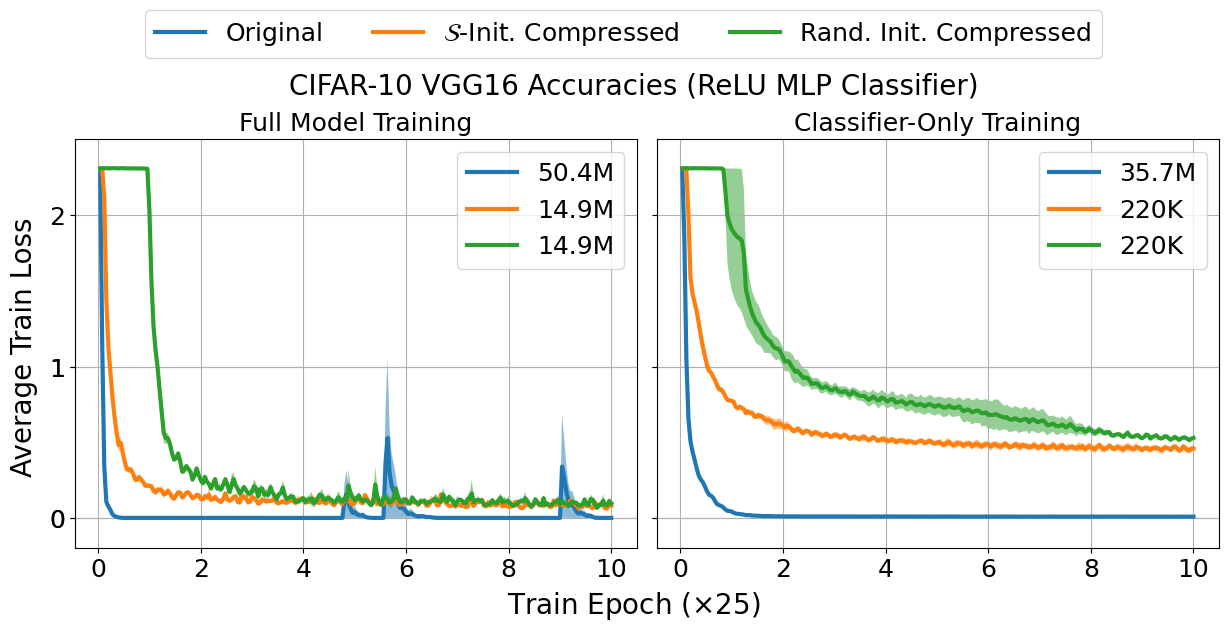

In [75]:
lw = 3

savefig = False

save_net_dir = act + '_vgg16_' + init + '_init_scale_' + str(init_scale)
save_dir = os.path.join('./figs', data_dir, save_net_dir)
if savefig and not os.path.exists(save_dir):
    os.makedirs(save_dir)





# Full model train loss
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)

ax1.plot(np.arange(1, epochs + 1), mean_orig_train_losses, label='Original', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_orig_train_losses - std_orig_train_losses, mean_orig_train_losses + std_orig_train_losses, alpha=0.5, linewidth=lw)

ax1.plot(np.arange(1, epochs + 1), mean_comp_train_losses, label=r'$\mathcal{S}$-Init. Compressed', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_comp_train_losses - std_comp_train_losses, mean_comp_train_losses + std_comp_train_losses, alpha=0.5, linewidth=lw)

ax1.plot(np.arange(1, epochs + 1), mean_comp_rand_train_losses, label='Rand. Init. Compressed', linewidth=lw)
ax1.fill_between(np.arange(1, epochs + 1), mean_comp_rand_train_losses - std_comp_rand_train_losses, mean_comp_rand_train_losses + std_comp_rand_train_losses, alpha=0.5, linewidth=lw)


xticks = np.linspace(0, epochs, (epochs // 50) + 1)
xticklabels = np.linspace(0, epochs // 25, epochs // 50 + 1, dtype=int)

ax1.set_xticks(xticks, labels=xticklabels, fontsize=18)
ax1.set_yticks(np.linspace(0, 2, 5, dtype=int), labels=np.linspace(0, 2, 5, dtype=int), fontsize=18)
ax1.set_ylim([-0.2, 2.5])


ax1.set_title('Full Model Training', fontsize=18)
ax1.grid('on')
ax1.legend([num_full_params, '_', num_comp_params, '_', num_comp_params], fontsize=18) #, bbox_to_anchor=(0.2, 0.3))

# Frozen conv train loss
ax2 = fig.add_subplot(122, sharey=ax1)

ax2.plot(np.arange(1, epochs + 1), mean_fc_orig_train_losses, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_fc_orig_train_losses - std_fc_orig_train_losses, mean_fc_orig_train_losses + std_fc_orig_train_losses, alpha=0.5, linewidth=lw)

ax2.plot(np.arange(1, epochs + 1), mean_fc_comp_train_losses, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_fc_comp_train_losses - std_fc_comp_train_losses, mean_fc_comp_train_losses + std_fc_comp_train_losses, alpha=0.5, linewidth=lw)

ax2.plot(np.arange(1, epochs + 1), mean_fc_comp_rand_train_losses, linewidth=lw)
ax2.fill_between(np.arange(1, epochs + 1), mean_fc_comp_rand_train_losses - std_fc_comp_rand_train_losses, mean_fc_comp_rand_train_losses + std_fc_comp_rand_train_losses, alpha=0.5, linewidth=lw)


ax2.set_xticks(xticks, labels=xticklabels, fontsize=18)
plt.setp(ax2.get_yticklabels(), visible=False)
#ax2.set_yticks([]) #, labels=np.linspace(0, 90, 10, dtype=int), fontsize=12)
#ax2.set_yticks(np.arange(90 + 1, 9), labels=np.arange(100 + 1, 10), fontsize=12)
#ax2.set_ylim([0, 90])

#ax2.set_xlabel(r'Train Epoch ($\times 10$)', fontsize=12)
#ax2.set_ylabel('Test Accuracy', fontsize=12)
ax2.set_title('Classifier-Only Training', fontsize=18)
ax2.grid('on')
ax2.legend([fc_num_full_params, '_', fc_num_comp_params, '_', fc_num_comp_params], fontsize=18) #, loc='center')

plt.tight_layout()
fig.suptitle(data_map[dataset] + " VGG16 Accuracies (" + act + " MLP Classifier)", fontsize=20, y=1.05)
fig.supxlabel(r'Train Epoch ($\times 25$)', fontsize=20, y=-0.05) #xticks(xticks, labels=xticklabels, fontsize=12)
fig.supylabel('Average Train Loss', fontsize=20, x=-0.02)
fig.legend(ncol=3, fontsize=18, bbox_to_anchor=(0.9, 1.2))
if savefig:
    plt.savefig(os.path.join(save_dir, 'train_losses.pdf'), bbox_inches='tight')
plt.show()
plt.close()